# Will It Fit? Predicting Clothing Fit on RentTheRunway

**CSE 158/258 — Assignment 2** · Team: Ansh, Chloe, Harshitha, Vanshika

**Task.** Before a customer rents a garment in a given size, predict whether it will be reported as **small**, **fit** or **large**.

**Roadmap.** This notebook follows the five graded sections of the presentation:

| § | Section | Presenter |
|---|---|---|
| 1 | Predictive task, metrics, baselines, validity | Vanshika |
| 2 | Data, exploratory analysis, preprocessing | Ansh |
| 3 | Modeling | Chloe (baselines, 1-LV, logistic) · Harshitha (gradient boosting, text) |
| 4 | Evaluation | Chloe · Harshitha |
| 5 | Related work and conclusions | Vanshika |

All reusable code lives in the `a2` package in this repository (`src/a2/`: `data.py`, `features.py`, `models.py`, `evaluate.py`), with unit tests in `tests/`. This notebook imports it and walks through key pieces inline.

**Results at a glance (held-out test set, 19,254 rentals):**
- Our best pre-rental model, **gradient boosting on profile + history features**, reaches **Avg AUC 0.775** and **Macro-F1 0.567**. The comparison points are the item-history baseline (0.744 / 0.542), our 1-LV latent-size reproduction (0.711 / 0.513) and the majority class (0.500 / 0.283). The gains are significant under a paired bootstrap.
- It's the best model for **new customers too** (AUC 0.765 for the 42% of test rentals from customers never seen in training), because it relies mostly on the **item's** fit history.
- Accuracy is misleading here: always predicting "fit" scores 73.6% accuracy but 0 F1 on the classes that matter.
- A **post-hoc** model reading the review text gets AUC 0.854. Reviews only exist after the rental, so it isn't a usable predictor, but it shows there's real fit signal that body measurements and history don't capture.

In [1]:
import inspect, time, warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from a2 import data, evaluate, features, models
from a2.data import FIT_LABELS, load_dataset, load_raw, split, targets
from a2.evaluate import (average_auc, bootstrap_auc_difference, decide, macro_f1, report,
                         results_table, tune_weights)
from a2.features import FeatureBuilder
from a2.models import (GBMFit, ItemMajority, LatentSize, LogisticFit, MajorityClass, TextFit,
                       UserMajority)

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)

# --- one consistent chart style; small/fit/large use a diverging red-gray-blue scale ---
FIT_COLORS = {"small": "#e34948", "fit": "#a9a7a0", "large": "#2a78d6"}
INK, INK2, MUTED, GRID, AXIS, SURFACE, ACCENT = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": INK2, "text.color": INK,
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

def stacked_fit_bars(ax, shares, title):
    # 100% stacked horizontal bars (rows = groups, columns = small/fit/large shares)
    left = np.zeros(len(shares))
    for c in FIT_LABELS:
        ax.barh(shares.index, shares[c], left=left, color=FIT_COLORS[c], label=c,
                edgecolor=SURFACE, linewidth=1.5, height=0.7)
        left += shares[c].to_numpy()
    for i, (s, l) in enumerate(zip(shares["small"], shares["large"])):
        ax.text(0.005, i, f"{s:.0%}", va="center", ha="left", color="white", fontsize=8)
        ax.text(0.995, i, f"{l:.0%}", va="center", ha="right", color="white", fontsize=8)
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_title(title)

---
## 1. Predictive task

**Why it matters.** Fit is the main reason clothing is returned. For a rental service like RentTheRunway, a garment that arrives in the wrong size means an unhappy customer at an event (weddings, formal affairs) and a wasted rental slot. A model that flags *"this dress will probably run small on you"* before checkout lets the site recommend a different size.

**Formulation.** 3-class classification. Each example is one rental transaction *(customer, item, size)* with label `fit ∈ {small, fit, large}`.

**Inputs we allow.** Only information available **before** the rental:
- the customer's profile (height, weight, bust size, age, body type) and the order (item, rented size, category, occasion);
- the **training history**: how this item, this item-in-this-size and this customer were rated in *past* (training) rentals.

**Inputs we deliberately exclude:** `rating`, `review_text`, `review_summary` and `review_date`. They are written after the customer has worn the garment, so a real system can't use them before checkout. We do fit a review-text model in §4, but only as a **post-hoc comparison**, to show how much of the fit signal ends up in the reviews.

**Evaluation** (justified in §4):
- **Average AUC**: mean one-vs-rest ROC AUC over the three classes. It doesn't depend on a decision threshold, and it's the metric used in the dataset's paper (Misra et al., 2018), so we can compare with them.
- **Macro-F1**: F1 averaged equally over the classes, for the hard decisions a retailer acts on. 74% of rentals are "fit", so **accuracy is misleading**: always predicting "fit" already scores 74%.
- Accuracy and per-class F1 for context.

**Baselines** (from the course): majority class, the item's fit history, the customer's fit history, and the 1-LV latent "true size" model from the size-recommendation literature.

**How we assess validity:**
1. A fixed-seed random **80/10/10 train/validation/test split**, the same protocol as Misra et al. All tuning (hyperparameters, decision weights) uses validation only, and the **test set is scored once**, at the end.
2. History features for training rows are built **out-of-fold**, so a row's own label never leaks into its features.
3. **Paired bootstrap confidence intervals** for the differences between models on the test set.
4. A **cold-start breakdown**: 42% of test rentals come from customers we have never seen, so we check where each model still works.

In [2]:
rows = load_dataset()                 # parse + clean all 192,544 rentals (src/a2/data.py)
train, valid, test = split(rows)      # fixed seed 0, 80/10/10
y_train, y_valid, y_test = targets(train), targets(valid), targets(test)
pd.DataFrame({"rentals": [len(train), len(valid), len(test)]}, index=["train", "valid", "test"]).T

,train,valid,test
rentals,154036,19254,19254


---
## 2. Data, exploratory analysis and preprocessing

### Context
**RentTheRunway** is an online service where customers rent designer clothing for occasions. After a rental, customers can leave a review recording **how the item fit** (small / fit / large), a 2–10 rating, free text, and their own body measurements. The dataset was collected and released by **Misra, Wan & McAuley (RecSys 2018)** for research on product size recommendation, and is available from the [UCSD recommender-systems dataset page](https://cseweb.ucsd.edu/~jmcauley/datasets.html) (`renttherunway_final_data.json.gz`, JSON lines).

Our counts reproduce the paper's Table 1 exactly. Following the paper, a **"product" is an item in a specific size**:

In [3]:
users = Counter(r["user_id"] for r in rows)
items = Counter(r["item_id"] for r in rows)
products = Counter((r["item_id"], r["size"]) for r in rows)
fits = Counter(r["fit"] for r in rows)
stats = pd.DataFrame({
    "ours": [len(rows), len(users), len(products), fits["small"] / len(rows), fits["large"] / len(rows),
             sum(c == 1 for c in users.values()), sum(c == 1 for c in products.values()), len(items)],
    "Misra et al. 2018, Table 1": [192544, 105571, 30815, 0.134, 0.128, 71824, 8023, None],
}, index=["# transactions", "# customers", "# products (item × size)", "fraction small", "fraction large",
          "# customers with 1 transaction", "# products with 1 transaction", "# distinct items"])
stats.style.format(lambda v: "—" if pd.isna(v) else (f"{v:.3f}" if v < 1 else f"{v:,.0f}"))

,ours,"Misra et al. 2018, Table 1"
# transactions,"192,544","192,544"
# customers,"105,571","105,571"
# products (item × size),"30,815","30,815"
fraction small,0.134,0.134
fraction large,0.128,0.128
# customers with 1 transaction,"71,824","71,824"
# products with 1 transaction,"8,023","8,023"
# distinct items,"5,850",—


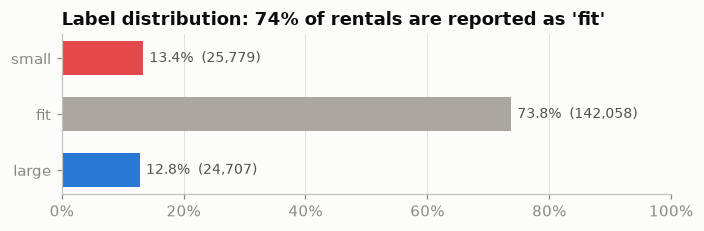

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 2.2))
shares = pd.Series(fits)[FIT_LABELS] / len(rows)
ax.barh(FIT_LABELS, shares, color=[FIT_COLORS[c] for c in FIT_LABELS], height=0.6)
for i, (c, s) in enumerate(shares.items()):
    ax.text(s + 0.01, i, f"{s:.1%}  ({fits[c]:,})", va="center", color=INK2, fontsize=9)
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Label distribution: 74% of rentals are reported as 'fit'")
plt.tight_layout(); plt.show()

**Takeaway:** the classes are imbalanced. Small and large are roughly equally rare (13% each). That's why we report Macro-F1 and AUC rather than accuracy.

### Preprocessing
Raw fields are strings in inconsistent formats. `a2.data.clean()` parses them into numbers, keeps the raw fields, and turns anything missing or unparseable into `None`:

| Raw field | Example | Parsed |
|---|---|---|
| `weight` | `"137lbs"` | `weight_lbs = 137.0` |
| `height` | `5' 8"` | `height_in = 68` |
| `bust size` | `"34d"` | `bust_band = 34`, `bust_cup = "d"` (→ ordinal 0–11) |
| `age`, `size`, `rating` | `"28"`, `14`, `"10"` | integers |
| `review_date` | `"April 20, 2016"` | `datetime` |

We confirmed that **every non-missing value in all 192,544 rows parses**. One cleaning decision: **ages outside 14–90 are set to missing**. The raw data contains ages 0–9 and 91–117, which are clearly entry errors. Ages 14–17 are kept, since teenagers do rent prom dresses.

In [5]:
raw = load_raw()
fields = {"weight": "weight_lbs", "height": "height_in", "bust size": "bust_band", "age": "age",
          "body type": "body type", "rented for": "rented for", "rating": "rating", "size": "size"}
miss = pd.DataFrame({
    "missing in raw data": [sum(r.get(f) in (None, "") for r in raw) / len(raw) for f in fields],
    "missing after cleaning": [sum(r.get(c) in (None, "missing") for r in rows) / len(rows) for c in fields.values()],
}, index=list(fields))
ages = Counter(r.get("age") for r in raw)
print(f"ages set to missing by the 14-90 rule: {sum(n for a, n in ages.items() if a and not 14 <= int(a) <= 90)}")
miss.style.format("{:.1%}")

ages set to missing by the 14-90 rule: 151


,missing in raw data,missing after cleaning
weight,15.6%,15.6%
height,0.4%,0.4%
bust size,9.6%,9.6%
age,0.5%,0.6%
body type,7.6%,7.6%
rented for,0.0%,0.0%
rating,0.0%,0.0%
size,0.0%,0.0%


Weight is missing for 16% of customers and bust size for 10%. We **don't drop** these rows. Missing values are imputed (logistic regression) or handled natively (gradient boosting), and each model also gets a *missing-indicator* feature.

### What drives fit?

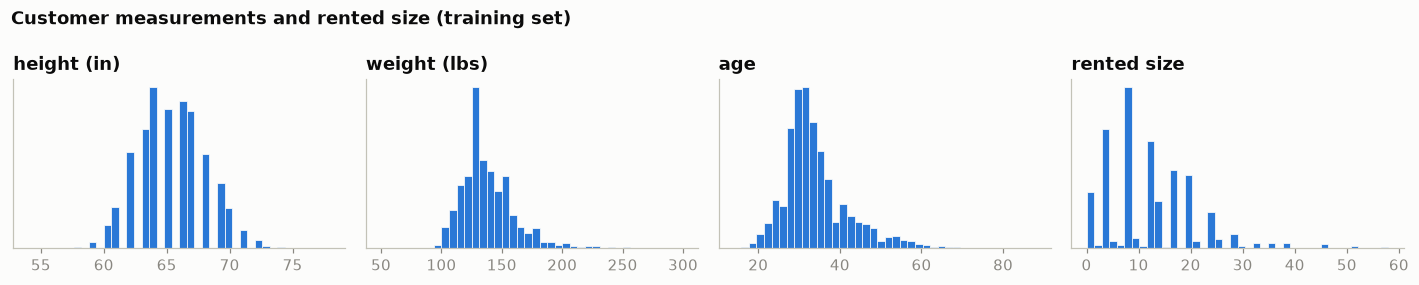

In [6]:
df = pd.DataFrame([{k: r.get(k) for k in ["fit", "weight_lbs", "height_in", "age", "size", "category", "body type", "rented for"]}
                   for r in train])
df[["body type", "rented for"]] = df[["body type", "rented for"]].fillna("missing")
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, (col, label) in zip(axes, [("height_in", "height (in)"), ("weight_lbs", "weight (lbs)"), ("age", "age"), ("size", "rented size")]):
    ax.hist(df[col].dropna(), bins=40, color=ACCENT, edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(label); ax.grid(axis="x", visible=False); ax.set_yticks([])
fig.suptitle("Customer measurements and rented size (training set)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

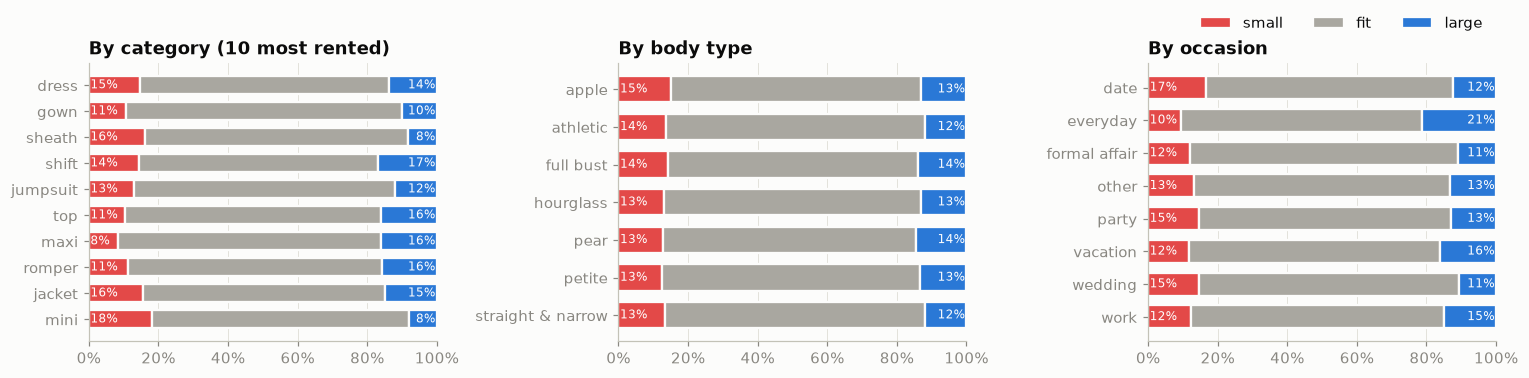

In [7]:
def fit_shares(frame, col, top=None, min_n=500):
    t = pd.crosstab(frame[col], frame["fit"])[FIT_LABELS]
    t = t[t.sum(axis=1) >= min_n]
    if top: t = t.loc[t.sum(axis=1).nlargest(top).index]
    return t.div(t.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
stacked_fit_bars(axes[0], fit_shares(df, "category", top=10), "By category (10 most rented)")
stacked_fit_bars(axes[1], fit_shares(df[df["body type"] != "missing"], "body type"), "By body type")
stacked_fit_bars(axes[2], fit_shares(df[df["rented for"] != "missing"], "rented for"), "By occasion")
axes[2].legend(ncol=3, loc="upper right", bbox_to_anchor=(1, 1.22))
plt.tight_layout(); plt.show()

**Takeaway:** the customer-level and category-level attributes barely move the fit distribution. Every category, body type and occasion sits near 13% small / 74% fit / 13% large. **Fit isn't a property of the customer or of the garment on its own. It depends on how the two match.** That suggests modelling the *interaction*, for example a customer's usual size compared with the size they rented, or their body compared with the bodies this product fit before.

The next chart tests that. For customers with other training rentals, we compare the size they rented with their usual size (computed out-of-fold, using only their *other* rentals):

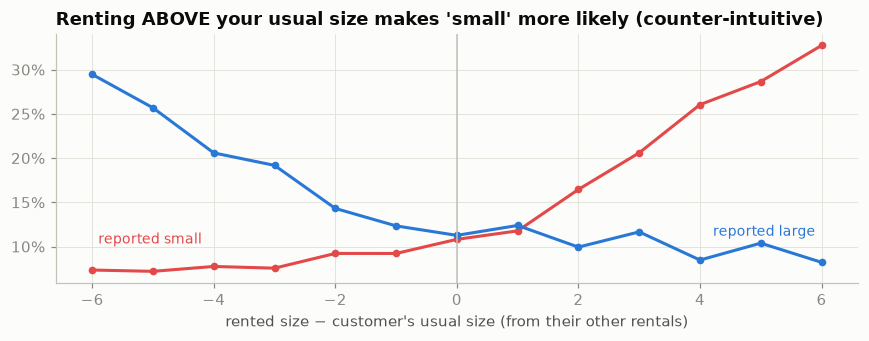

rows with a usual size available: 83,572 of 154,036


In [8]:
fb_eda = FeatureBuilder()
X_eda = fb_eda.fit_transform(train)
d = pd.DataFrame({"diff": X_eda["size_vs_user"].round().clip(-6, 6), "fit": y_train}).dropna()
t = pd.crosstab(d["diff"], d["fit"])[FIT_LABELS]
share = t.div(t.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(share.index, share["small"], color=FIT_COLORS["small"], lw=2, marker="o", ms=4)
ax.plot(share.index, share["large"], color=FIT_COLORS["large"], lw=2, marker="o", ms=4)
ax.text(share.index[0] + 0.1, share["small"].iloc[0] + 0.03, "reported small", color=FIT_COLORS["small"], fontsize=9)
ax.text(share.index[-1] - 0.1, share["large"].iloc[-1] + 0.03, "reported large", color=FIT_COLORS["large"], fontsize=9, ha="right")
ax.axvline(0, color=AXIS, lw=1)
ax.set_xlabel("rented size − customer's usual size (from their other rentals)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Renting ABOVE your usual size makes 'small' more likely (counter-intuitive)")
plt.tight_layout(); plt.show()
print(f"rows with a usual size available: {len(d):,} of {len(train):,}")

This is a strong relationship, but **in the opposite direction from what we expected**. Customers who rent *above* their usual size report "small" more often (up to 33%), and those who rent *below* it report "large" more often. We checked two explanations:

1. **Self-selection.** Customers size up on garments they *expect* to run small, and the correction isn't enough. The table below supports this partly: items rented by people who sized up have a higher historical "small" rate.
2. **The size scale isn't universal.** Misra et al. note that sizes are *standardised per item into an order-preserving scale*, so "+2" on one brand isn't "+2" on another. Even **within items that have the same tendency** to run small, sizing up still raises P(small) (e.g. from 22% to 41% for items that often run small). So the raw size difference mixes brand conventions with the customer's choice.

Either way, the signal is real and predictive, and tree models can learn its direction from data. This is one reason we compare the customer with the **item's own history** (its small/large rates, and the bodies of people it fit) rather than relying on sizes alone.

In [9]:
d["item_p_small"] = X_eda["item_p_small"]
d["chose"] = pd.cut(d["diff"], [-99, -1.5, 1.5, 99], labels=["sized down (≤ −2)", "usual (−1..1)", "sized up (≥ 2)"])
d["item tendency"] = pd.qcut(d["item_p_small"], 3, labels=["item rarely small", "item sometimes small", "item often small"])
pd.crosstab([d["item tendency"], d["chose"]], d["fit"], normalize="index")[["small", "large"]].style.format("{:.1%}")

### Sparsity and cold start

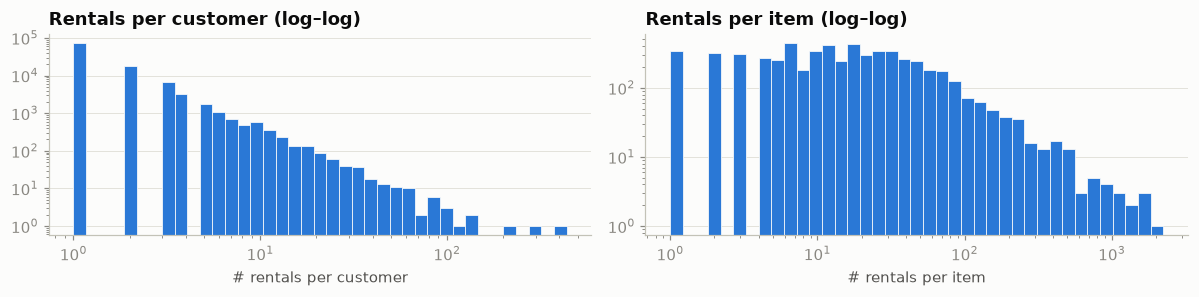

,share
test rentals by a customer unseen in training,41.6%
test rentals of an item unseen in training,0.3%
test rentals of a product (item × size) unseen in training,5.5%


In [10]:
seen_users = Counter(r["user_id"] for r in train)
seen_items = {r["item_id"] for r in train}
seen_prods = {(r["item_id"], r["size"]) for r in train}
cold = pd.Series({
    "test rentals by a customer unseen in training": np.mean([r["user_id"] not in seen_users for r in test]),
    "test rentals of an item unseen in training": np.mean([r["item_id"] not in seen_items for r in test]),
    "test rentals of a product (item × size) unseen in training": np.mean([(r["item_id"], r["size"]) not in seen_prods for r in test]),
}).to_frame("share")

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, counts, name in [(axes[0], users, "customer"), (axes[1], items, "item")]:
    v = np.array(list(counts.values()))
    ax.hist(v, bins=np.logspace(0, np.log10(v.max() + 1), 40), color=ACCENT, edgecolor=SURFACE, linewidth=0.5)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(axis="x", visible=False)
    ax.set_title(f"Rentals per {name} (log–log)"); ax.set_xlabel(f"# rentals per {name}")
plt.tight_layout(); plt.show()
cold.style.format("{:.1%}")

**Takeaways from §2:**
- **Customers are very sparse**: 68% have exactly one rental, and 42% of test rentals come from customers never seen in training. Customer-level models (user history, user latent factors) can't help them.
- **Items are dense**: fewer than 1% of test rentals involve an unseen item, so item-level fit history is available almost everywhere.
- **Fit depends on the customer–product match**, not on profile attributes alone. Our features therefore compare the customer with the product's history.

---
## 3. Modeling

**ML formulation.** Input *x* = (customer profile, order, training history); output = a probability distribution over {small, fit, large}. Every model is trained to minimise **multiclass log-loss** (cross-entropy), or the equivalent ordinal likelihood for 1-LV. Hard labels then come from a class-weighted argmax, with the weights tuned on validation for Macro-F1 (§4).

Every model in `a2.models` has the same interface, `fit(train_rows)` then `predict_proba(rows)` (columns small, fit, large), so they can all be compared with one evaluation function.

| Model | Idea | Pros | Cons |
|---|---|---|---|
| **Majority class** | Always "fit" | Trivial floor; shows why accuracy is misleading | No signal (AUC = 0.5) |
| **Item history** | The item's smoothed small/fit/large rates | Items are dense, so it almost always applies; captures "this dress runs small" | Ignores the customer and the size she chose |
| **User history** | The customer's smoothed rates | Captures customers who are hard to please | 42% of test customers have no history |
| **1-LV latent size** (Sembium et al. 2017) | Learn a "true size" *u_c* per customer and *v_p* per product; an ordinal logit on *z = u_c − v_p* | Principled and interpretable; the standard baseline in the literature | One number per entity can't capture shape (bust vs. hips); weak for cold customers |
| **Logistic regression** | Linear model on profile features, or on profile + history | Fast, interpretable coefficients | Linear: can't model interactions like "heavier than this product's fit renters" |
| **Gradient boosting** (ours) | Boosted trees on profile + history features | Learns non-linear interactions; handles missing values natively | Less interpretable (we use permutation importance) |
| **Review text** (post-hoc) | TF-IDF of the review → logistic regression | Shows how much fit information is in the review | **Not usable before the rental**; comparison only |

### Feature construction (`a2.features.FeatureBuilder`)
- **Profile:** height, weight, BMI, bust band, cup (ordinal), age, rented size, missing-value flags, and one-hot category, body type and occasion (values with fewer than 50 training rentals are grouped as "other").
- **History (computed from training data):** for the item, the product (item × size) and the customer: number of past rentals and smoothed P(small), P(large); rented size minus the customer's usual size and minus the item's typical size; and the customer's **weight, height and bust minus the averages of people this product fit**.

The key implementation detail is that **history features for training rows are computed out-of-fold** (5 folds). Each row's history comes only from the other folds, so its own label never leaks into its features, and training rows look like test rows: a customer with a single rental has *no* history in training, exactly as at test time. Smoothing pulls rates for rarely seen groups toward the global prior: $\hat p = (n_c + k\,p_c)/(n + k)$ with $k = 10$.

In [11]:
print(inspect.getsource(features._history))

def _history(hist, target, smoothing):
    """History features for `target` rows computed only from `hist` rows."""
    out = pd.DataFrame(index=target.index)
    prior = {c: float((hist["fit"] == c).mean()) for c in ("small", "large")}
    h = hist.assign(small=(hist["fit"] == "small").astype(float), large=(hist["fit"] == "large").astype(float))

    for name, keys in GROUPS.items():
        g = h.groupby(keys).agg(n=("fit", "size"), small=("small", "sum"), large=("large", "sum")).reset_index()
        m = target[keys].merge(g, on=keys, how="left").set_index(target.index)
        n = m["n"].fillna(0.0)
        out[f"{name}_n"] = n
        for c in ("small", "large"):
            p = (m[c] + smoothing * prior[c]) / (n + smoothing)
            out[f"{name}_p_{c}"] = p.where(n > 0)

    for name, keys in (("user", ["user_id"]), ("item", ["item_id"])):
        mean_size = h.groupby(keys)["size"].mean().rename("mean_size").reset_index()
        m = target[keys].merge(mean_size, on=keys, ho

### The 1-LV latent size model
For transaction *t* = (customer *c*, product *p*), let $z_t = u_c - v_p$, where *z* > 0 means the customer is "bigger" than the product, so it runs small. With learned thresholds $\theta_1 < \theta_2$, an **ordinal logistic** model gives

$$P(\text{large}) = \sigma(\theta_1 - z),\quad P(\text{fit}) = \sigma(\theta_2 - z) - \sigma(\theta_1 - z),\quad P(\text{small}) = 1 - \sigma(\theta_2 - z).$$

We minimise the negative log-likelihood plus an $L_2$ penalty $\lambda(\lVert u\rVert^2 + \lVert v\rVert^2)$ with L-BFGS and an analytic gradient (checked against finite differences in `tests/test_models.py`). We write $\theta_2 = \theta_1 + e^{\delta}$, which guarantees the thresholds stay ordered. Unseen customers or products get latent size 0, the average.

In [12]:
print(inspect.getsource(models._ordinal_loss_and_grad))

def _ordinal_loss_and_grad(params, ui, pi, y, n_u, n_p, reg):
    """Mean negative log-likelihood + reg * mean squared latents, and its gradient.
    params = [u (n_u), v (n_p), theta1, log(theta2 - theta1)]. y codes: 0 small, 1 fit, 2 large."""
    u, v = params[:n_u], params[n_u:n_u + n_p]
    theta1, delta = params[-2], params[-1]
    gap = np.exp(delta)
    z = u[ui] - v[pi]
    a, b = theta1 - z, theta1 + gap - z
    sa, sb = expit(a), expit(b)
    n = len(y)

    small, fit, large = y == 0, y == 1, y == 2
    nll = np.empty(n)
    nll[large] = np.logaddexp(0, -a[large])             # -log s(a)
    nll[small] = np.logaddexp(0, b[small])              # -log(1 - s(b))
    diff = np.maximum(sb[fit] - sa[fit], 1e-12)
    nll[fit] = -np.log(diff)

    d_a, d_b = np.zeros(n), np.zeros(n)
    d_a[large] = -(1 - sa[large])
    d_b[small] = sb[small]
    d_a[fit] = sa[fit] * (1 - sa[fit]) / diff
    d_b[fit] = -sb[fit] * (1 - sb[fit]) / diff
    d_z = -(d_a + d_b)

    loss = nll.sum() / n

**Tuning λ on validation.** With 105k customers, most of whom rent once, regularisation matters:

In [13]:
lv_rows = []
for reg in [0.1, 1.0, 5.0, 20.0]:
    m = LatentSize(reg=reg).fit(train)
    lv_rows.append({"λ": reg, "valid Avg AUC": average_auc(y_valid, m.predict_proba(valid)), "converged": m.converged_})
    if reg == 1.0: lv = m
pd.DataFrame(lv_rows)

,λ,valid Avg AUC,converged
0,0.1,0.6997,False
1,1.0,0.7012,True
2,5.0,0.6867,True
3,20.0,0.6718,True


λ = 1 gives the best validation AUC and converges; that's the model we keep. (With λ = 0.1, L-BFGS hits its iteration limit while still overfitting single-rental customers.)

### Fitting all models

In [14]:
fitted, timing = {}, {}
for name, model in [
    ("Majority class", MajorityClass()),
    ("Item history", ItemMajority()),
    ("User history", UserMajority()),
    ("1-LV latent size", lv),
    ("Logistic (profile only)", LogisticFit(profile_only=True)),
    ("Logistic (profile + history)", LogisticFit(profile_only=False)),
    ("Gradient boosting (profile + history)", GBMFit()),
]:
    t0 = time.time()
    if name != "1-LV latent size":
        model.fit(train)
    fitted[name] = model
    timing[name] = time.time() - t0
pd.Series(timing, name="fit time (s)").round(1).to_frame()

,fit time (s)
Majority class,0.1
Item history,0.2
User history,0.6
1-LV latent size,0.0
Logistic (profile only),4.6
Logistic (profile + history),4.8
Gradient boosting (profile + history),14.1


**Gradient-boosting sensitivity.** We checked whether the result depends on hyperparameters (early stopping on a 10% slice of training data chooses the number of trees):

In [15]:
sens = []
for kw in [dict(), dict(max_leaf_nodes=15), dict(max_leaf_nodes=63), dict(l2_regularization=10.0)]:
    m = fitted["Gradient boosting (profile + history)"] if not kw else GBMFit(**kw).fit(train)
    sens.append({"setting": str(kw or "default (31 leaves, lr 0.05, l2 1)"), "trees": m.clf_.n_iter_,
                 "valid Avg AUC": average_auc(y_valid, m.predict_proba(valid))})
pd.DataFrame(sens)

,setting,trees,valid Avg AUC
0,"default (31 leaves, lr 0.05, l2 1)",181,0.7748
1,{'max_leaf_nodes': 15},297,0.7750
2,{'max_leaf_nodes': 63},130,0.7746
3,{'l2_regularization': 10.0},169,0.7754


All settings land within ±0.001 AUC, so the result isn't fragile, and we keep the defaults.

---
## 4. Evaluation

### Why these metrics
- **Accuracy is the wrong headline**: always predicting "fit" scores 74%, but it never warns anyone, which is the whole point of the model.
- **Average AUC** measures how well a model *ranks* rentals by risk of being small, fit or large, without choosing a threshold. It matches the dataset paper, so we can compare.
- **Macro-F1** measures the *decisions*. A retailer has to commit to "warn: runs small" or not, and Macro-F1 rewards getting the rare classes right as much as the common one.
- **Decision rule.** Picking the most probable class almost always picks "fit". We instead predict $\arg\max_k w_k\,\hat p_k$, with weights $w_\text{small}, w_\text{large}$ chosen on **validation** to maximise Macro-F1 ($w_\text{fit} = 1$). This is the same threshold trade-off a retailer makes: higher weights catch more true small/large cases (recall) at the cost of more false alarms (precision).

### Validation results (used for all model choices)

In [16]:
proba_valid = {n: m.predict_proba(valid) for n, m in fitted.items()}
weights = {n: tune_weights(y_valid, p) for n, p in proba_valid.items()}
val_rows = []
for n, p in proba_valid.items():
    r = report(n, y_valid, decide(p, weights[n]), p)
    r["weights (small, fit, large)"] = weights[n]
    val_rows.append(r)
results_table(val_rows)

,model,Avg AUC,Macro-F1,Accuracy,F1 small,F1 fit,F1 large,"weights (small, fit, large)"
0,Gradient boosting (profile + history),0.7748,0.5686,0.7035,0.4458,0.8002,0.4598,"(2.5, 1.0, 3.0)"
1,Logistic (profile + history),0.7660,0.5657,0.7158,0.4337,0.8118,0.4517,"(2.5, 1.0, 3.0)"
2,Item history,0.7381,0.5384,0.7070,0.3818,0.8083,0.4250,"(2.5, 1.0, 2.5)"
3,1-LV latent size,0.7012,0.5060,0.6665,0.3658,0.7764,0.3759,"(4.0, 1.0, 4.0)"
4,Logistic (profile only),0.6129,0.4236,0.6228,0.2750,0.7580,0.2377,"(4.0, 1.0, 4.0)"
5,User history,0.5404,0.3759,0.5950,0.1757,0.7471,0.2049,"(5.0, 1.0, 5.0)"
6,Majority class,0.5000,0.2829,0.7370,0.0000,0.8486,0.0000,"(1.0, 1.0, 1.0)"


### Final test results (test set scored once)

In [17]:
proba_test = {n: m.predict_proba(test) for n, m in fitted.items()}
test_table = results_table([report(n, y_test, decide(p, weights[n]), p) for n, p in proba_test.items()])
test_table

,model,Avg AUC,Macro-F1,Accuracy,F1 small,F1 fit,F1 large
0,Gradient boosting (profile + history),0.7746,0.5673,0.6985,0.4442,0.7945,0.4632
1,Logistic (profile + history),0.7643,0.5631,0.7098,0.4309,0.8063,0.4522
2,Item history,0.7442,0.5423,0.7079,0.3940,0.8086,0.4243
3,1-LV latent size,0.7112,0.5129,0.6703,0.3760,0.7784,0.3843
4,Logistic (profile only),0.6124,0.4191,0.6175,0.2710,0.7537,0.2327
5,User history,0.5369,0.3708,0.5893,0.1766,0.7412,0.1945
6,Majority class,0.5000,0.2825,0.7355,0.0000,0.8476,0.0000


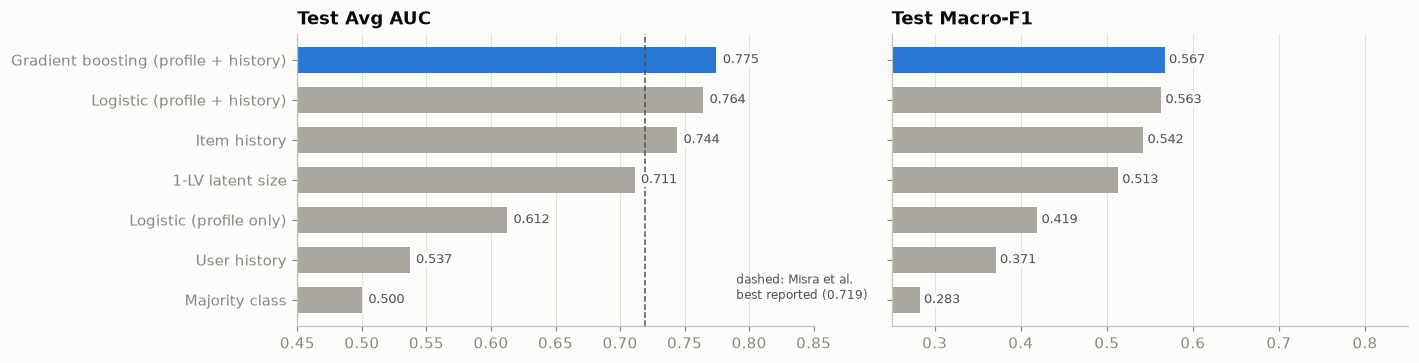

In [18]:
order = test_table.sort_values("Avg AUC")
best = order["model"].iloc[-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for ax, metric in zip(axes, ["Avg AUC", "Macro-F1"]):
    colors = [ACCENT if m == best else "#a9a7a0" for m in order["model"]]
    ax.barh(order["model"], order[metric], color=colors, height=0.65)
    for i, v in enumerate(order[metric]):
        ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK2, zorder=3,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=0.5))
    ax.set_xlim(0.25 if metric == "Macro-F1" else 0.45, 0.85); ax.grid(axis="y", visible=False)
    ax.set_title(f"Test {metric}")
axes[0].axvline(0.719, color=INK2, lw=1, ls="--", zorder=1)
axes[0].text(0.79, 0.3, "dashed: Misra et al.\nbest reported (0.719)", fontsize=8, color=INK2, va="center")
plt.tight_layout(); plt.show()

### Is the improvement real? Paired bootstrap on the test set
We resample the 19,254 test rentals 1,000 times and recompute the AUC *difference* between two models on the same resample. If the 95% interval excludes 0, the gap isn't luck.

In [19]:
gbm = "Gradient boosting (profile + history)"
ci = []
for other in ["Logistic (profile + history)", "Item history", "1-LV latent size"]:
    lo, hi = bootstrap_auc_difference(y_test, proba_test[gbm], proba_test[other], n_boot=1000)
    ci.append({"comparison": f"{gbm} − {other}",
               "Δ Avg AUC": average_auc(y_test, proba_test[gbm]) - average_auc(y_test, proba_test[other]),
               "95% CI": f"[{lo:+.4f}, {hi:+.4f}]"})
pd.DataFrame(ci)

,comparison,Δ Avg AUC,95% CI
0,Gradient boosting (profile + history) − Logist...,0.0103,"[+0.0075, +0.0129]"
1,Gradient boosting (profile + history) − Item h...,0.0304,"[+0.0262, +0.0347]"
2,Gradient boosting (profile + history) − 1-LV l...,0.0634,"[+0.0578, +0.0691]"


### Cold start: where does each model work?
We split test rentals by how many training rentals the **customer** has:

In [20]:
def bucket(n): return "0 (new customer)" if n == 0 else "1–2" if n <= 2 else "3+"
b = np.array([bucket(seen_users.get(r["user_id"], 0)) for r in test])
yt = np.array(y_test)
cold_rows = []
for name in ["Item history", "User history", "1-LV latent size", "Logistic (profile + history)", gbm]:
    row = {"model": name}
    for g in ["0 (new customer)", "1–2", "3+"]:
        row[g] = average_auc(yt[b == g], proba_test[name][b == g])
    cold_rows.append(row)
cold_tab = pd.DataFrame(cold_rows).set_index("model")
cold_tab.loc["share of test rentals"] = [np.mean(b == g) for g in cold_tab.columns]
cold_tab

,0 (new customer),1–2,3+
model,,,
Item history,0.7366,0.7484,0.7485
User history,0.5000,0.5337,0.5713
1-LV latent size,0.7217,0.7070,0.7004
Logistic (profile + history),0.7609,0.7648,0.7677
Gradient boosting (profile + history),0.7651,0.7783,0.7818
share of test rentals,0.4157,0.2913,0.2931


### What the best model gets right and wrong

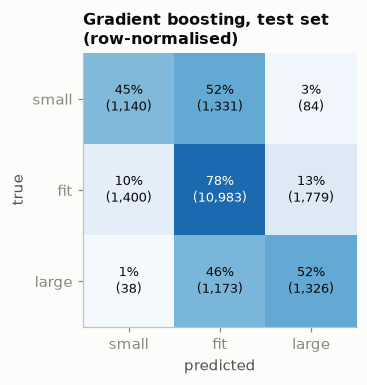

In [21]:
pred = decide(proba_test[gbm], weights[gbm])
cm = pd.crosstab(pd.Series(y_test, name="true"), pd.Series(pred, name="predicted")).loc[FIT_LABELS, FIT_LABELS]
cm_norm = cm.div(cm.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.imshow(cm_norm.to_numpy(), cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        v = cm_norm.iat[i, j]
        ax.text(j, i, f"{v:.0%}\n({cm.iat[i, j]:,})", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.55 else INK)
ax.set_xticks(range(3), FIT_LABELS); ax.set_yticks(range(3), FIT_LABELS); ax.grid(False)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Gradient boosting, test set\n(row-normalised)", fontsize=10.5)
plt.tight_layout(); plt.show()

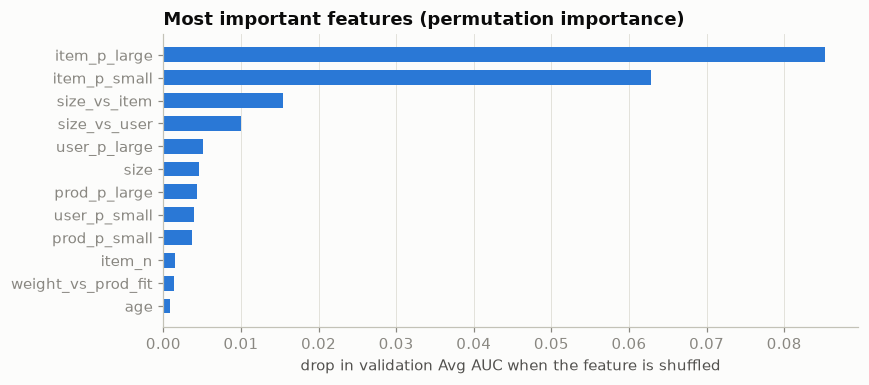

In [22]:
imp = fitted[gbm].feature_importance(valid, n_repeats=2).head(12)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(imp.index[::-1], imp.values[::-1], color=ACCENT, height=0.65)
ax.grid(axis="y", visible=False); ax.set_xlabel("drop in validation Avg AUC when the feature is shuffled")
ax.set_title("Most important features (permutation importance)")
plt.tight_layout(); plt.show()

### Post-hoc comparison: what do reviews know?
The review text is written *after* the rental, so this model can't be used before checkout. It shows how much fit information customers write down, which is effectively an upper reference point for what profile-and-history models miss.

In [23]:
text = TextFit().fit(train)
p_text_valid, p_text_test = text.predict_proba(valid), text.predict_proba(test)
w_text = tune_weights(y_valid, p_text_valid)
display(results_table([report("Review text (post-hoc, NOT pre-rental)", y_test, decide(p_text_test, w_text), p_text_test),
                       report(gbm, y_test, decide(proba_test[gbm], weights[gbm]), proba_test[gbm])]))
pd.DataFrame({k: v[:12] for k, v in text.top_words(12).items()})

,model,Avg AUC,Macro-F1,Accuracy,F1 small,F1 fit,F1 large
0,"Review text (post-hoc, NOT pre-rental)",0.8540,0.6883,0.8033,0.6000,0.8741,0.5907
1,Gradient boosting (profile + history),0.7746,0.5673,0.6985,0.4442,0.7945,0.4632


,small,fit,large
0,runs small,true to,large
1,size up,runs true,size down
2,tight,tts,big
3,small,true,runs large
4,little small,to size,sizing down
5,bit small,ran true,size smaller
6,small side,reviews that,runs big
7,sized up,run short,run large
8,snug,than normally,baggy
9,sizing up,not too,sized down


### Discussion of the evaluation
- **Baselines vs. models.** Every model beats the trivial baseline. **Gradient boosting is best on both headline metrics** (test Avg AUC 0.775, Macro-F1 0.567). It beats logistic regression with the same features by +0.010 AUC (95% CI [+0.008, +0.013]), the item-history baseline by +0.030 ([+0.026, +0.035]) and 1-LV by +0.063 ([+0.058, +0.069]). All three intervals exclude 0. Validation and test numbers agree to within ±0.01, so there's no sign of overfitting to validation.
- **History, not body, carries the signal.** Logistic regression on *profile only* gets AUC 0.612. Adding history features brings it to 0.764. Permutation importance agrees: the item's historical small/large rates are the most important features by far, followed by size relative to the item and to the customer. Body measurements matter mainly *relative to* the people a product fit.
- **The customer side is weak.** User history alone barely beats chance (0.537): most customers have one or two rentals, and the smoothed estimate stays near the prior.
- **Cold start.** Gradient boosting stays best for brand-new customers (0.765) and improves with more history (0.782 for 3+ rentals). Interestingly, 1-LV does *better* for new customers (0.722) than for returning ones (0.700). For a new customer it falls back on the product's latent size, which is well estimated, while the latent size of a customer with one or two rentals is noisy and overfit even with λ tuned.
- **Error structure.** The confusion matrix shows the model almost never confuses *small* with *large* (3% and 1% of those rows). Errors fall into the neighbouring "fit" class, as you'd expect for an ordinal problem. Recall is 45% for small and 52% for large, against 0% for the majority baseline.
- **The decision trade-off.** The tuned weights (≈2.5–3× for small and large) trade accuracy (73.6% → 69.9%) for much higher Macro-F1 (0.283 → 0.567). A retailer choosing between *"warn more customers"* and *"cry wolf less"* would set these weights from the business cost of a return versus an unnecessary warning.
- **Post-hoc text.** The review model (AUC 0.854, Macro-F1 0.688) shows how much fit information customers *write*. Its top n-grams are the vocabulary of fit ("runs small", "size up", "tight", "snug" vs. "runs large", "size down", "loose", "baggy"). Reviews of *other* customers for the same item would be available before a new rental, which suggests a legitimate future feature (see conclusions).

---
## 5. Related work

**This dataset.** RentTheRunway (and ModCloth) were introduced by **Misra, Wan & McAuley, *Decomposing Fit Semantics for Product Size Recommendation in Metric Spaces*, RecSys 2018**. Their method, K-LF-ML, learns *K*-dimensional latent factors for customers and products, trained with an ordinal hinge loss whose product factors are constrained to be ordered by size. It then applies **metric learning (Large-Margin Nearest Neighbour) with prototyping** to handle label imbalance and classifies with k-NN. Their protocol matches ours: a random 80/10/10 split, tuning on validation, and **average AUC** as the metric.

**Prior approaches to fit prediction:**
- **Sembium et al., *Recommending Product Sizes to Customers*, RecSys 2017** (Amazon): one latent "true size" per customer and product, with fit modelled from their difference. This is **1-LV**, which we re-implement; it's the standard baseline.
- **Sembium et al., *Bayesian Models for Product Size Recommendations*, WWW 2018**: Bayesian ordinal (logit/probit) extensions of the same idea.
- **Abdulla & Borar, *Size Recommendation System for Fashion E-commerce*, KDD Workshop 2017**: skip-gram embeddings of customers and products, which relies on platform-specific features.

**Comparison with reported results** (average AUC on RentTheRunway, from Misra et al. Table 2):

In [24]:
ours = test_table.set_index("model")["Avg AUC"]
related = pd.DataFrame([
    ("Misra et al. 2018", "1-LV-LR (one latent size, Sembium et al. 2017)", 0.61),
    ("Misra et al. 2018", "K-LV-LR (K latent sizes)", 0.676),
    ("Misra et al. 2018", "K-LF-LR (latent fit semantics)", 0.672),
    ("Misra et al. 2018", "K-LV-ML (metric learning)", 0.681),
    ("Misra et al. 2018", "K-LF-ML (their proposed method)", 0.719),
    ("ours", "1-LV latent size (our re-implementation)", ours["1-LV latent size"]),
    ("ours", "Item history baseline", ours["Item history"]),
    ("ours", "Logistic (profile + history)", ours["Logistic (profile + history)"]),
    ("ours", "Gradient boosting (profile + history)", ours[gbm]),
], columns=["source", "method", "Avg AUC (test)"])
related.style.format({"Avg AUC (test)": "{:.3f}"})

,source,method,Avg AUC (test)
0,Misra et al. 2018,"1-LV-LR (one latent size, Sembium et al. 2017)",0.610
1,Misra et al. 2018,K-LV-LR (K latent sizes),0.676
2,Misra et al. 2018,K-LF-LR (latent fit semantics),0.672
3,Misra et al. 2018,K-LV-ML (metric learning),0.681
4,Misra et al. 2018,K-LF-ML (their proposed method),0.719
5,ours,1-LV latent size (our re-implementation),0.711
6,ours,Item history baseline,0.744
7,ours,Logistic (profile + history),0.764
8,ours,Gradient boosting (profile + history),0.775


**How our results compare.** Our numbers are *higher* than those reported, but we don't claim to beat Misra et al., for three reasons:
1. **Our 1-LV re-implementation scores 0.711 against their 0.61** for nominally the same model. The paper runs 1-LV in the setting of Sembium et al., with logistic regression on the latent score. We fit an ordinal likelihood directly, with tuned L2 regularisation. Implementation details clearly matter a lot.
2. The paper doesn't spell out exactly how "average AUC" is averaged, and our random split is a different random draw with the same 80/10/10 proportions.
3. So the fairest comparison is **within** our own protocol: on identical data and metric, adding item-level history and boosted trees improves on 1-LV by +0.063 AUC. For scale, the paper's method improves on *its* 1-LV by +0.109 and on K-LV / K-LF by +0.043 / +0.047 (its Table 2).

**Agreements with prior work:**
- Like Misra et al., we find that a single latent size (1-LV) is the weakest of the latent approaches, and that **label imbalance** is a central difficulty. They address it with metric learning and prototyping; we use validation-tuned decision weights, which is much simpler and directly optimises Macro-F1.
- Both works find **sparsity** is the key obstacle (68% of customers rent once). Our cold-start analysis adds that **pooling history at the item level** (across all sizes), instead of the item × size "product" used by latent-factor models, is a simple and strong way around it. 26% of products have a single transaction, but almost every test item has history.

**Where we differ:** prior fit models use only transaction IDs. We show that combining customer measurements with **relative** features (the customer vs. the people the product fit, and the rented size vs. the customer's usual size) inside a non-linear model gives most of the gain. We also report Macro-F1 and a cold-start breakdown, which the paper doesn't.

---
## Conclusions, limitations and next steps

**Conclusions.**
- Predicting fit before a rental is possible but hard. The best pre-rental model reaches **Avg AUC 0.775** and **Macro-F1 0.567**, a clear and statistically significant improvement over the trivial (0.500 / 0.283), item-history (0.744 / 0.542) and 1-LV latent-size (0.711 / 0.513) baselines.
- Most of the signal comes from **how a garment has fit other people**, especially people with similar bodies, rather than from the customer's profile alone.
- The model still works for **new customers**, which matters on a platform where most customers rent only once.

**Limitations.**
- **Labels are self-reported and subjective.** The same garment can be "fit" for one customer and "small" for another with similar measurements, which caps achievable accuracy.
- **Random split.** Following the paper, we split at random rather than by time, so some history features for a test rental can come from training rentals that happened *later*. A temporal split would be stricter and more realistic, and would likely lower all history-based scores somewhat.
- **The size scale is per-item, not universal**, which makes raw size comparisons across brands unreliable (see §2).
- We **tuned only lightly** (λ for 1-LV and a small grid for boosting), but the boosting results proved insensitive to its settings.

**Next steps.**
- **Item-level review features from past customers**: aggregate "runs small / runs large" language in *previous* reviews of the same item. This is legitimately available before a new rental, and the post-hoc text model suggests it carries strong signal.
- K-dimensional latent factors (K-LV / K-LF), used as extra features for the boosted model.
- A temporal train/test split and calibrated probabilities for showing "X% chance this runs small" to customers.

---
*Code: `src/a2/` (data, features, models, evaluation) with 60 unit tests in `tests/`. Reproduce with `uv sync && uv run pytest`, then run this notebook top to bottom (~4 min on a laptop).*